# Overview 



This notebook will demonstrate scRNA-seq preprocessing using data from hematopoiesis. (Paul, F., Arkin, Y., Giladi, A., Jaitin, D. A., Kenigsberg, E., Keren-Shaul, H., et al. (2015). Transcriptional Heterogeneity and Lineage Commitment in Myeloid Progenitors. Cell, 163(7), 1663–1677. http://doi.org/10.1016/j.cell.2015.11.013).

You can easily download this scRNA-seq data using Scanpy.

### Notebook file
Notebook file is available on CellOracle's GitHub page.
https://github.com/morris-lab/CellOracle/blob/master/docs/notebooks/03_scRNA-seq_data_preprocessing/scanpy_preprocessing_with_Paul_etal_2015_data.ipynb


### Steps

To preprocess the scRNA-seq data, we will do the following:

1. **Variable gene selection and normalization.**
2. **Log transformation.**  Like many preprocessing workflows, we need to log transform the data. However, CellOracle also needs the raw gene expression values, which we will store in an anndata layer.
3. **Cell clustering.** 
4. **Dimensional reduction.** We need to prepare the 2D embedding data. Please make sure that the 2D embedding properly represents the cell identities and processes of interest. Also, please consider the resolution and continuity of the data. CellOracle’s simulation results are only informative when the embedding is consistent with the questions being investigated.


### Caution

- This notebook is intended to help users **prepare the input data for CellOracle analysis**. This is **NOT** the CellOracle analysis itself. Also, this notebook does NOT use `celloracle` in this notebook.

- Instead, we use `Scanpy` and `Anndata` to process and store the scRNA-seq data. If you are new to these packages, please learn about them in advance.  

 - `Scanpy` documentation: https://scanpy.readthedocs.io/en/stable/
 - `Anndata` documentation: https://anndata.readthedocs.io/en/latest/


### Acknowledgement

- This scRNA-seq preprocessing notebook was made based on the Scanpy's tutorial.
https://scanpy-tutorials.readthedocs.io/en/latest/paga-paul15.html

# 0. Import libraries

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

/home/elicanter/miniconda3/envs/celloracle_env3/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.figsize"] = [6, 4.5]

# 1. Load data


In [3]:
# Download dataset. You can change the code blow to use your data.
adata = sc.datasets.paul15()

# 2. Filtering

In [4]:
# Only consider genes with more than 1 count
sc.pp.filter_genes(adata, min_counts=1)


In [5]:
adata.raw = adata
adata.layers["raw_count_int"] = adata.raw.X.copy()

In [6]:
adata.layers["raw_count_int"]

array([[0., 0., 0., ..., 0., 2., 0.],
       [0., 0., 1., ..., 0., 1., 0.],
       [1., 0., 3., ..., 2., 3., 0.],
       ...,
       [0., 0., 1., ..., 0., 0., 0.],
       [3., 0., 3., ..., 0., 1., 0.],
       [0., 0., 4., ..., 1., 1., 1.]], dtype=float32)

# 3. Normalization

In [7]:
# Normalize gene expression matrix with total UMI count per cell
sc.pp.normalize_per_cell(adata, key_n_counts='n_counts_all')

/tmp/ipykernel_26315/2400592225.py:2: FutureWarning: Use sc.pp.normalize_total instead
  sc.pp.normalize_per_cell(adata, key_n_counts='n_counts_all')
/home/elicanter/miniconda3/envs/celloracle_env3/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:588: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


# 4. Identification of highly variable genes

**This step is essential. Please do not skip this step.**

> Removing non-variable genes reduces the calculation time during the GRN reconstruction and simulation steps.
It also improves the overall accuracy of the GRN inference by removing noisy genes.
We recommend using the top 2000~3000 variable genes. 

In [8]:
# Select top 2000 highly-variable genes
filter_result = sc.pp.filter_genes_dispersion(adata.X,
                                              flavor='cell_ranger',
                                              n_top_genes=2000,
                                              log=False)

# Subset the genes
adata = adata[:, filter_result.gene_subset]

# Renormalize after filtering
sc.pp.normalize_per_cell(adata)

/tmp/ipykernel_26315/2689374920.py:2: FutureWarning: Use sc.pp.highly_variable_genes instead
  filter_result = sc.pp.filter_genes_dispersion(adata.X,
/tmp/ipykernel_26315/2689374920.py:11: FutureWarning: Use sc.pp.normalize_total instead
  sc.pp.normalize_per_cell(adata)
/home/elicanter/miniconda3/envs/celloracle_env3/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:585: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_n_counts] = counts_per_cell
/home/elicanter/miniconda3/envs/celloracle_env3/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:588: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


In [9]:
adata.layers["raw_count_int"]

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 1., 1., ..., 0., 0., 0.],
       [1., 3., 1., ..., 1., 2., 0.],
       ...,
       [0., 1., 0., ..., 0., 0., 0.],
       [3., 3., 5., ..., 0., 0., 0.],
       [0., 4., 1., ..., 0., 1., 1.]], dtype=float32)

# 5. Log transformation
- •	We need to log transform and scale the data before we calculate the principal components, clusters, and differentially expressed genes.


- We also need to **keep the non-transformed gene expression data in a separate anndata layer** before the log transformation. We will use this data for celloracle analysis later. 


In [10]:
adata.raw = adata
adata.layers["raw_count"] = adata.raw.X.copy()

# Log transformation and scaling
sc.pp.log1p(adata)
sc.pp.scale(adata)

In [11]:
adata

AnnData object with n_obs × n_vars = 2730 × 1999
    obs: 'paul15_clusters', 'n_counts_all', 'n_counts'
    var: 'n_counts', 'mean', 'std'
    uns: 'iroot', 'log1p'
    layers: 'raw_count_int', 'raw_count'

# 6. PCA and neighbor calculations
These calculations are necessary to perform the dimensionality reduction and clustering steps.

In [12]:
# PCA
sc.tl.pca(adata, svd_solver='arpack')

# Diffusion map
sc.pp.neighbors(adata, n_neighbors=4, n_pcs=20)

sc.tl.diffmap(adata)
# Calculate neihbors again based on diffusionmap 
sc.pp.neighbors(adata, n_neighbors=10, use_rep='X_diffmap')

# 7. Cell clustering

In [13]:
sc.tl.louvain(adata, resolution=0.8)

# 8. Dimensionality reduction using PAGA and force-directed graphs

The dimensionality reduction step requires careful consideration when preparing data for a CellOracle analysis. For a successful analysis, the embedding should recapitulate the cellular transition of interest.

Please choose an algorithm that can accurately represent the developmental trajectory of your data. We recommend using one of the following dimensional reduction algorithms (or trajectory inference algorithms).
 - UMAP: https://scanpy.readthedocs.io/en/stable/generated/scanpy.tl.umap.html#scanpy.tl.umap
 - TSNE: https://scanpy.readthedocs.io/en/stable/generated/scanpy.tl.tsne.html#scanpy.tl.tsne
 - Diffusion map: https://scanpy.readthedocs.io/en/stable/generated/scanpy.tl.diffmap.html#scanpy.tl.diffmap
 - Force-directed graph drawing: https://scanpy.readthedocs.io/en/stable/generated/scanpy.tl.draw_graph.html#scanpy.tl.draw_graph
 

In this example, we use the workflow introduced in the scanpy trajectory inference tutorial. https://scanpy-tutorials.readthedocs.io/en/latest/paga-paul15.html This method uses a combination of three algorithms:diffusion map, force-directed graph, and PAGA.
- Step1: Calculate the PAGA graph.The PAGA data will determine the initial cluster positions for the force-directed graph calculation.
- Step2: Calculate the force-directed graph. 



In [14]:
# PAGA graph construction
sc.tl.paga(adata, groups='louvain')

In [15]:
plt.rcParams["figure.figsize"] = [6, 4.5]

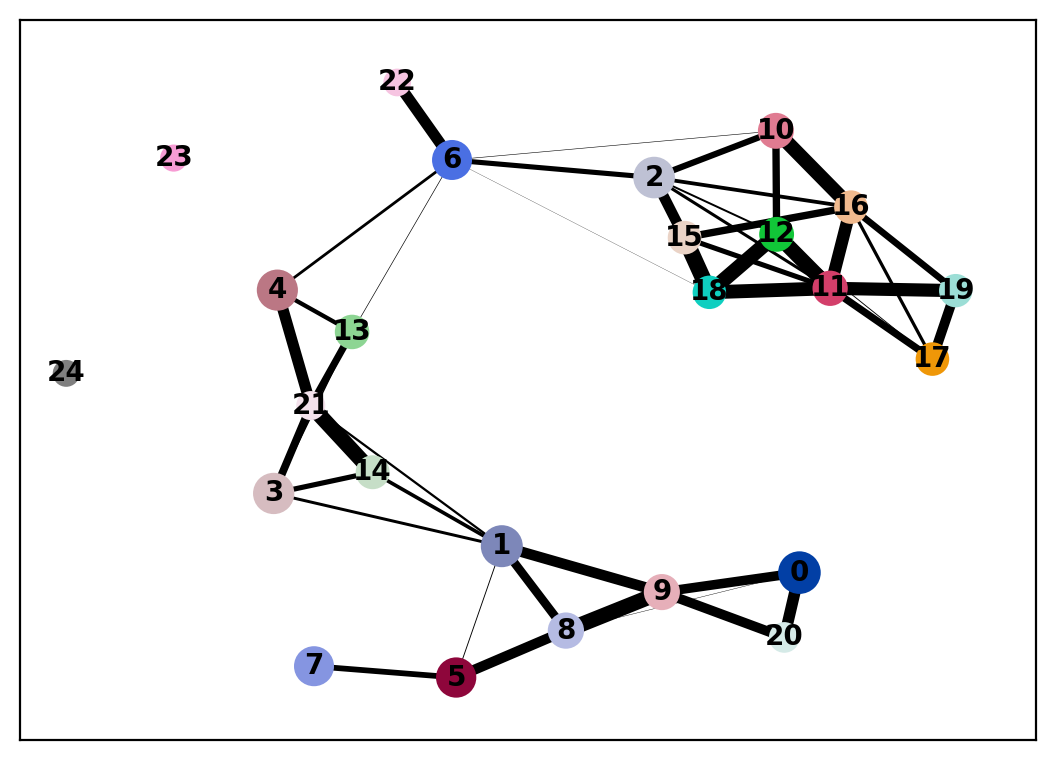

In [16]:
sc.pl.paga(adata)

In [18]:
sc.tl.draw_graph(adata, init_pos='paga', random_state=123)

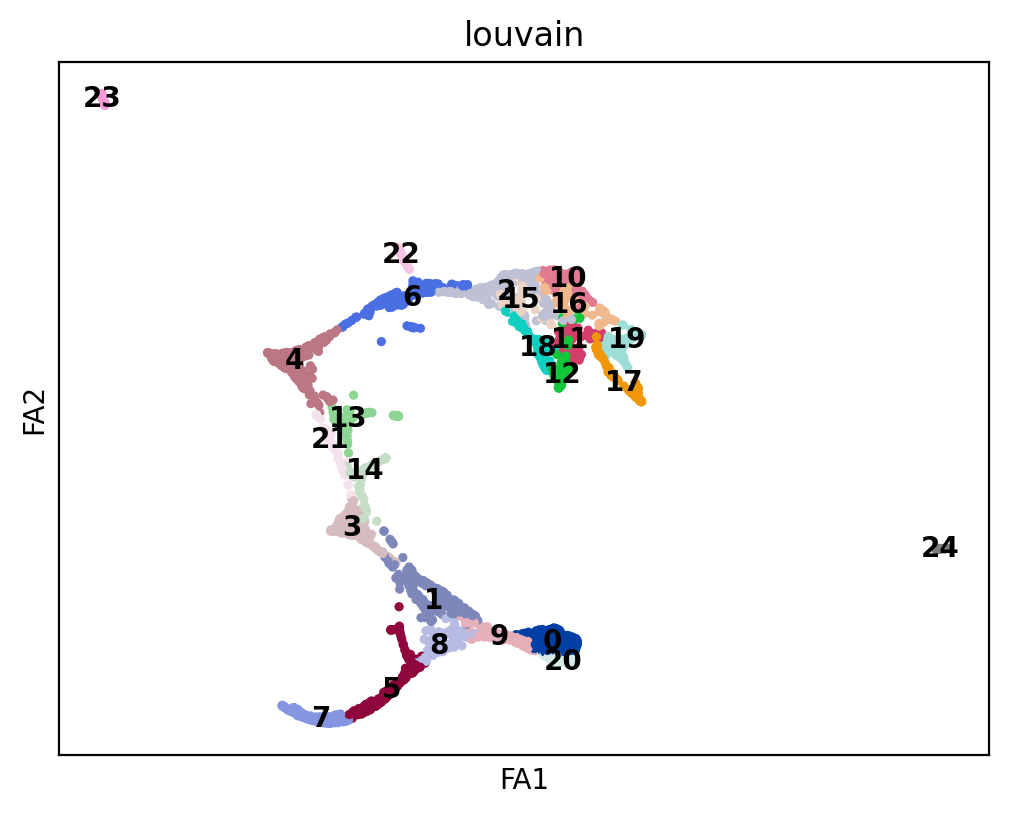

In [19]:
sc.pl.draw_graph(adata, color='louvain', legend_loc='on data')

# 9. Check data
## 9.1. Visualize marker gene expression

In [20]:
plt.rcParams["figure.figsize"] = [4.5, 4.5]

marker gene of Erythroids


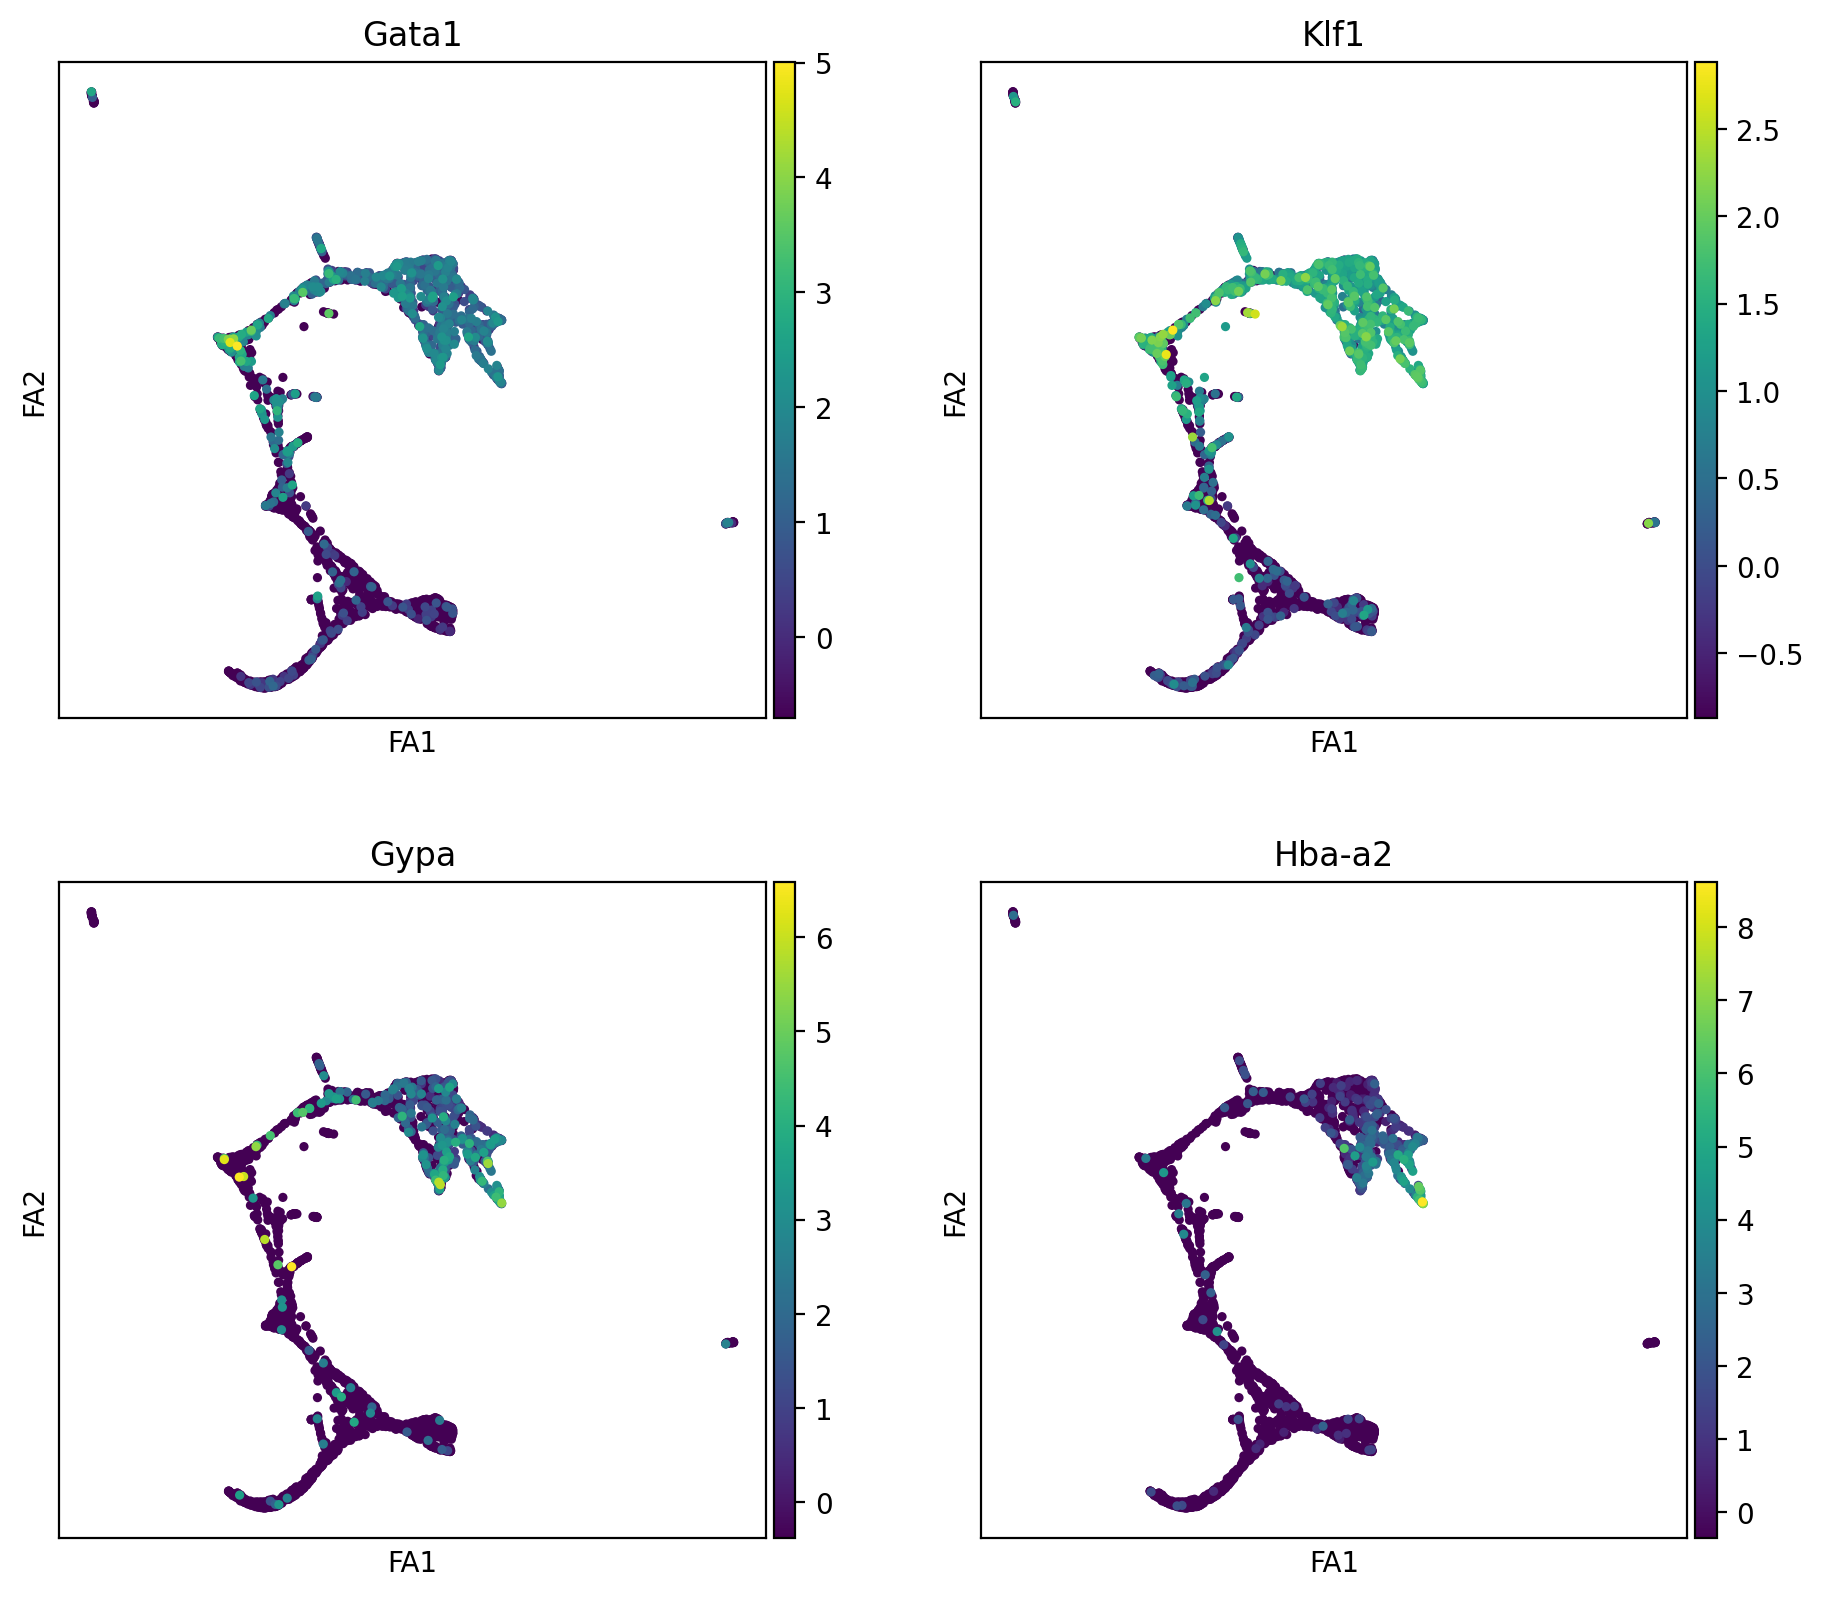

marker gene of Megakaryocytes


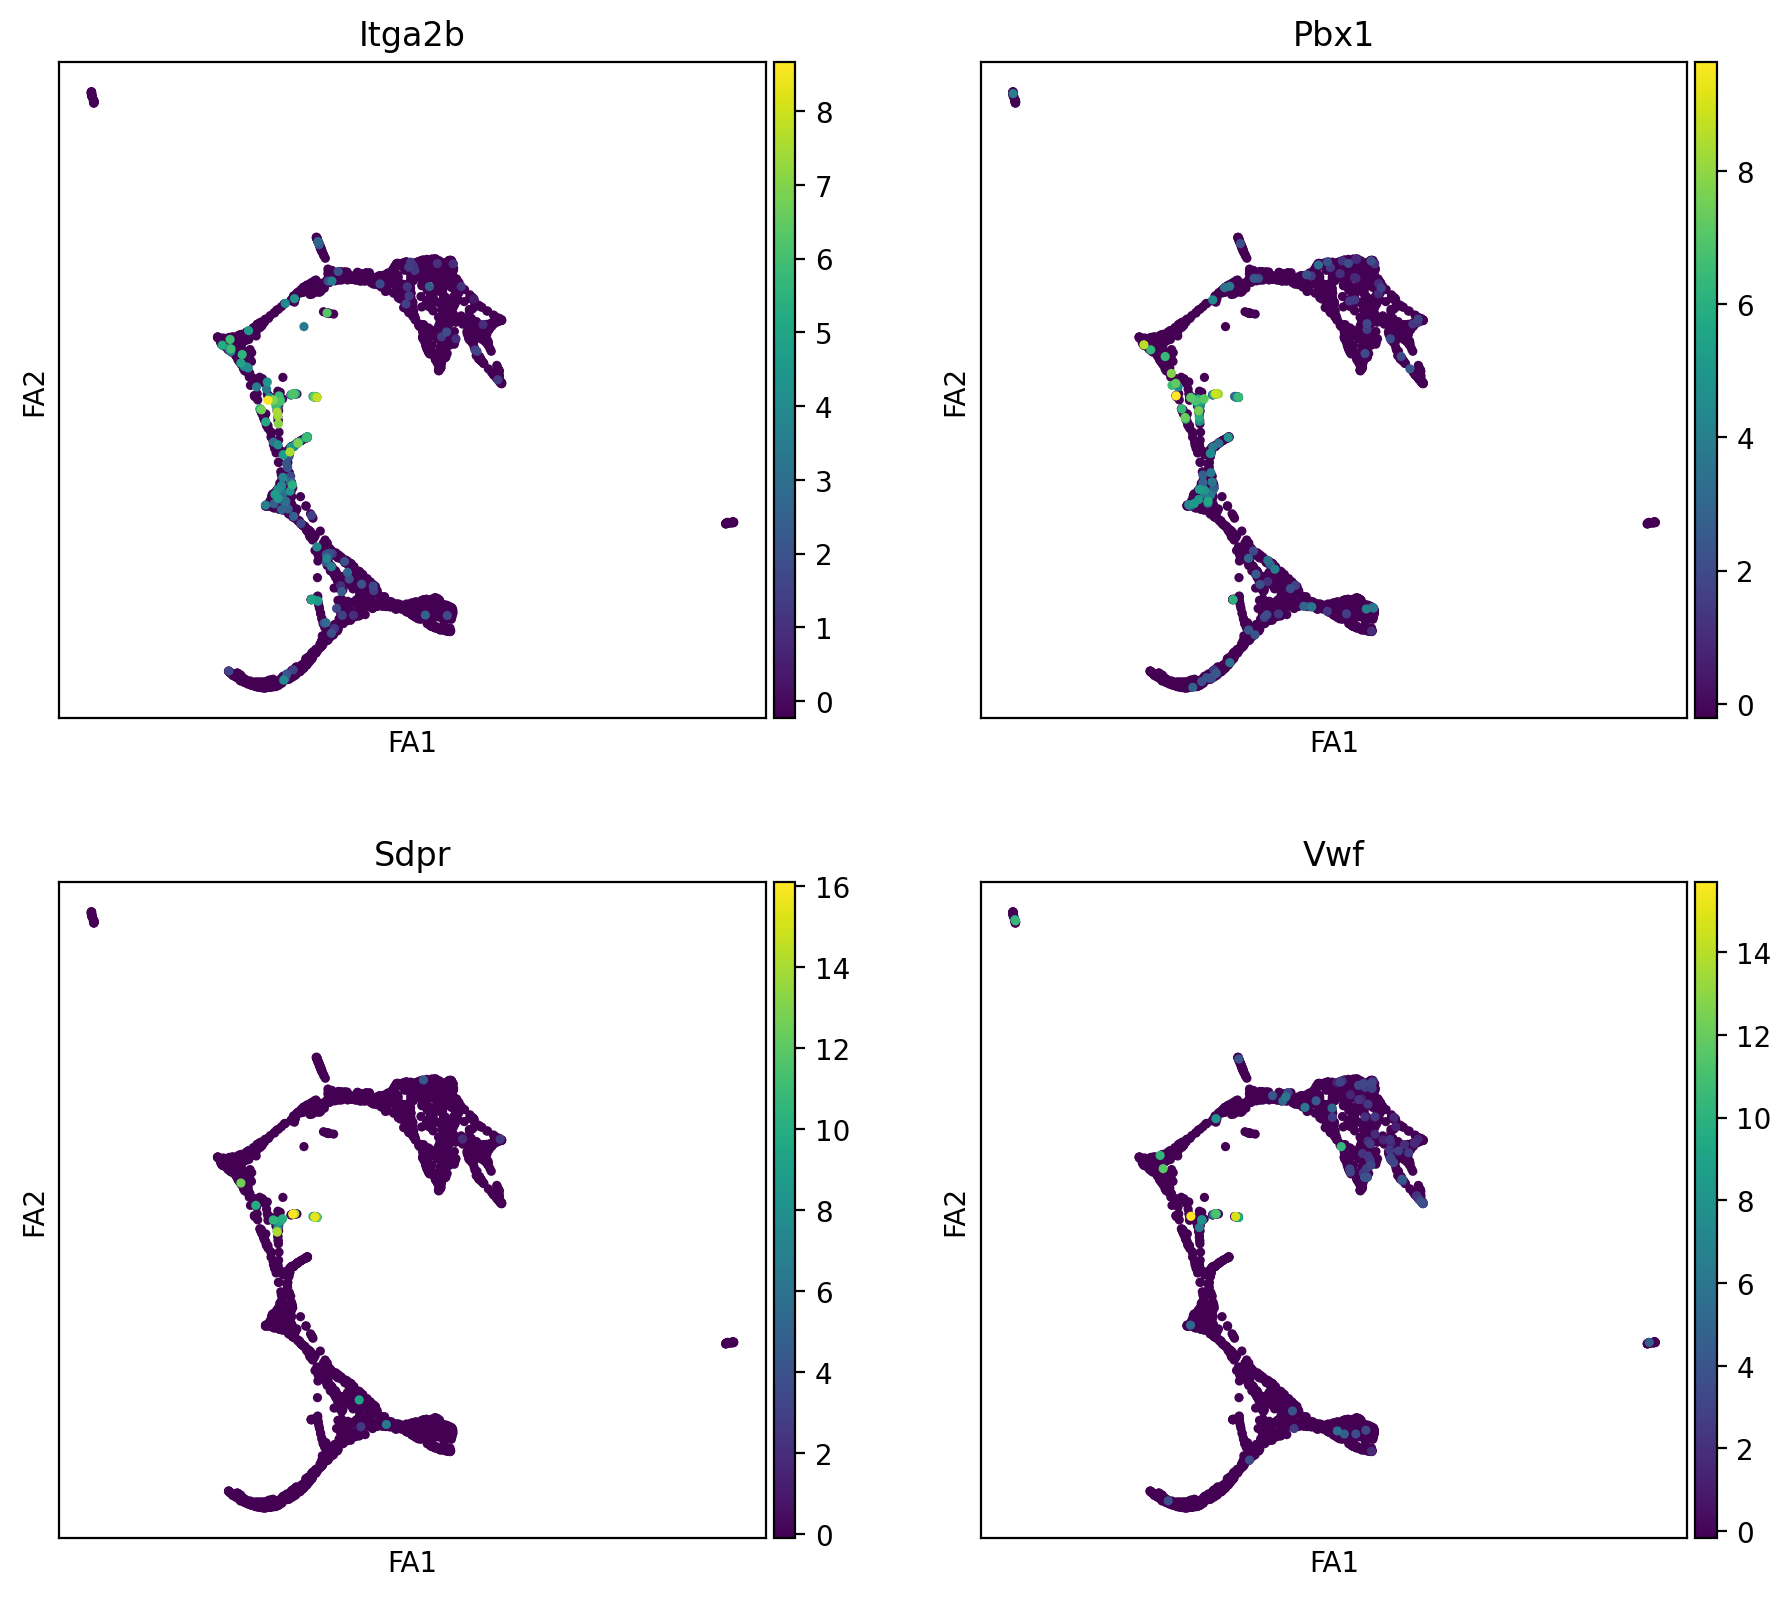

marker gene of Granulocytes


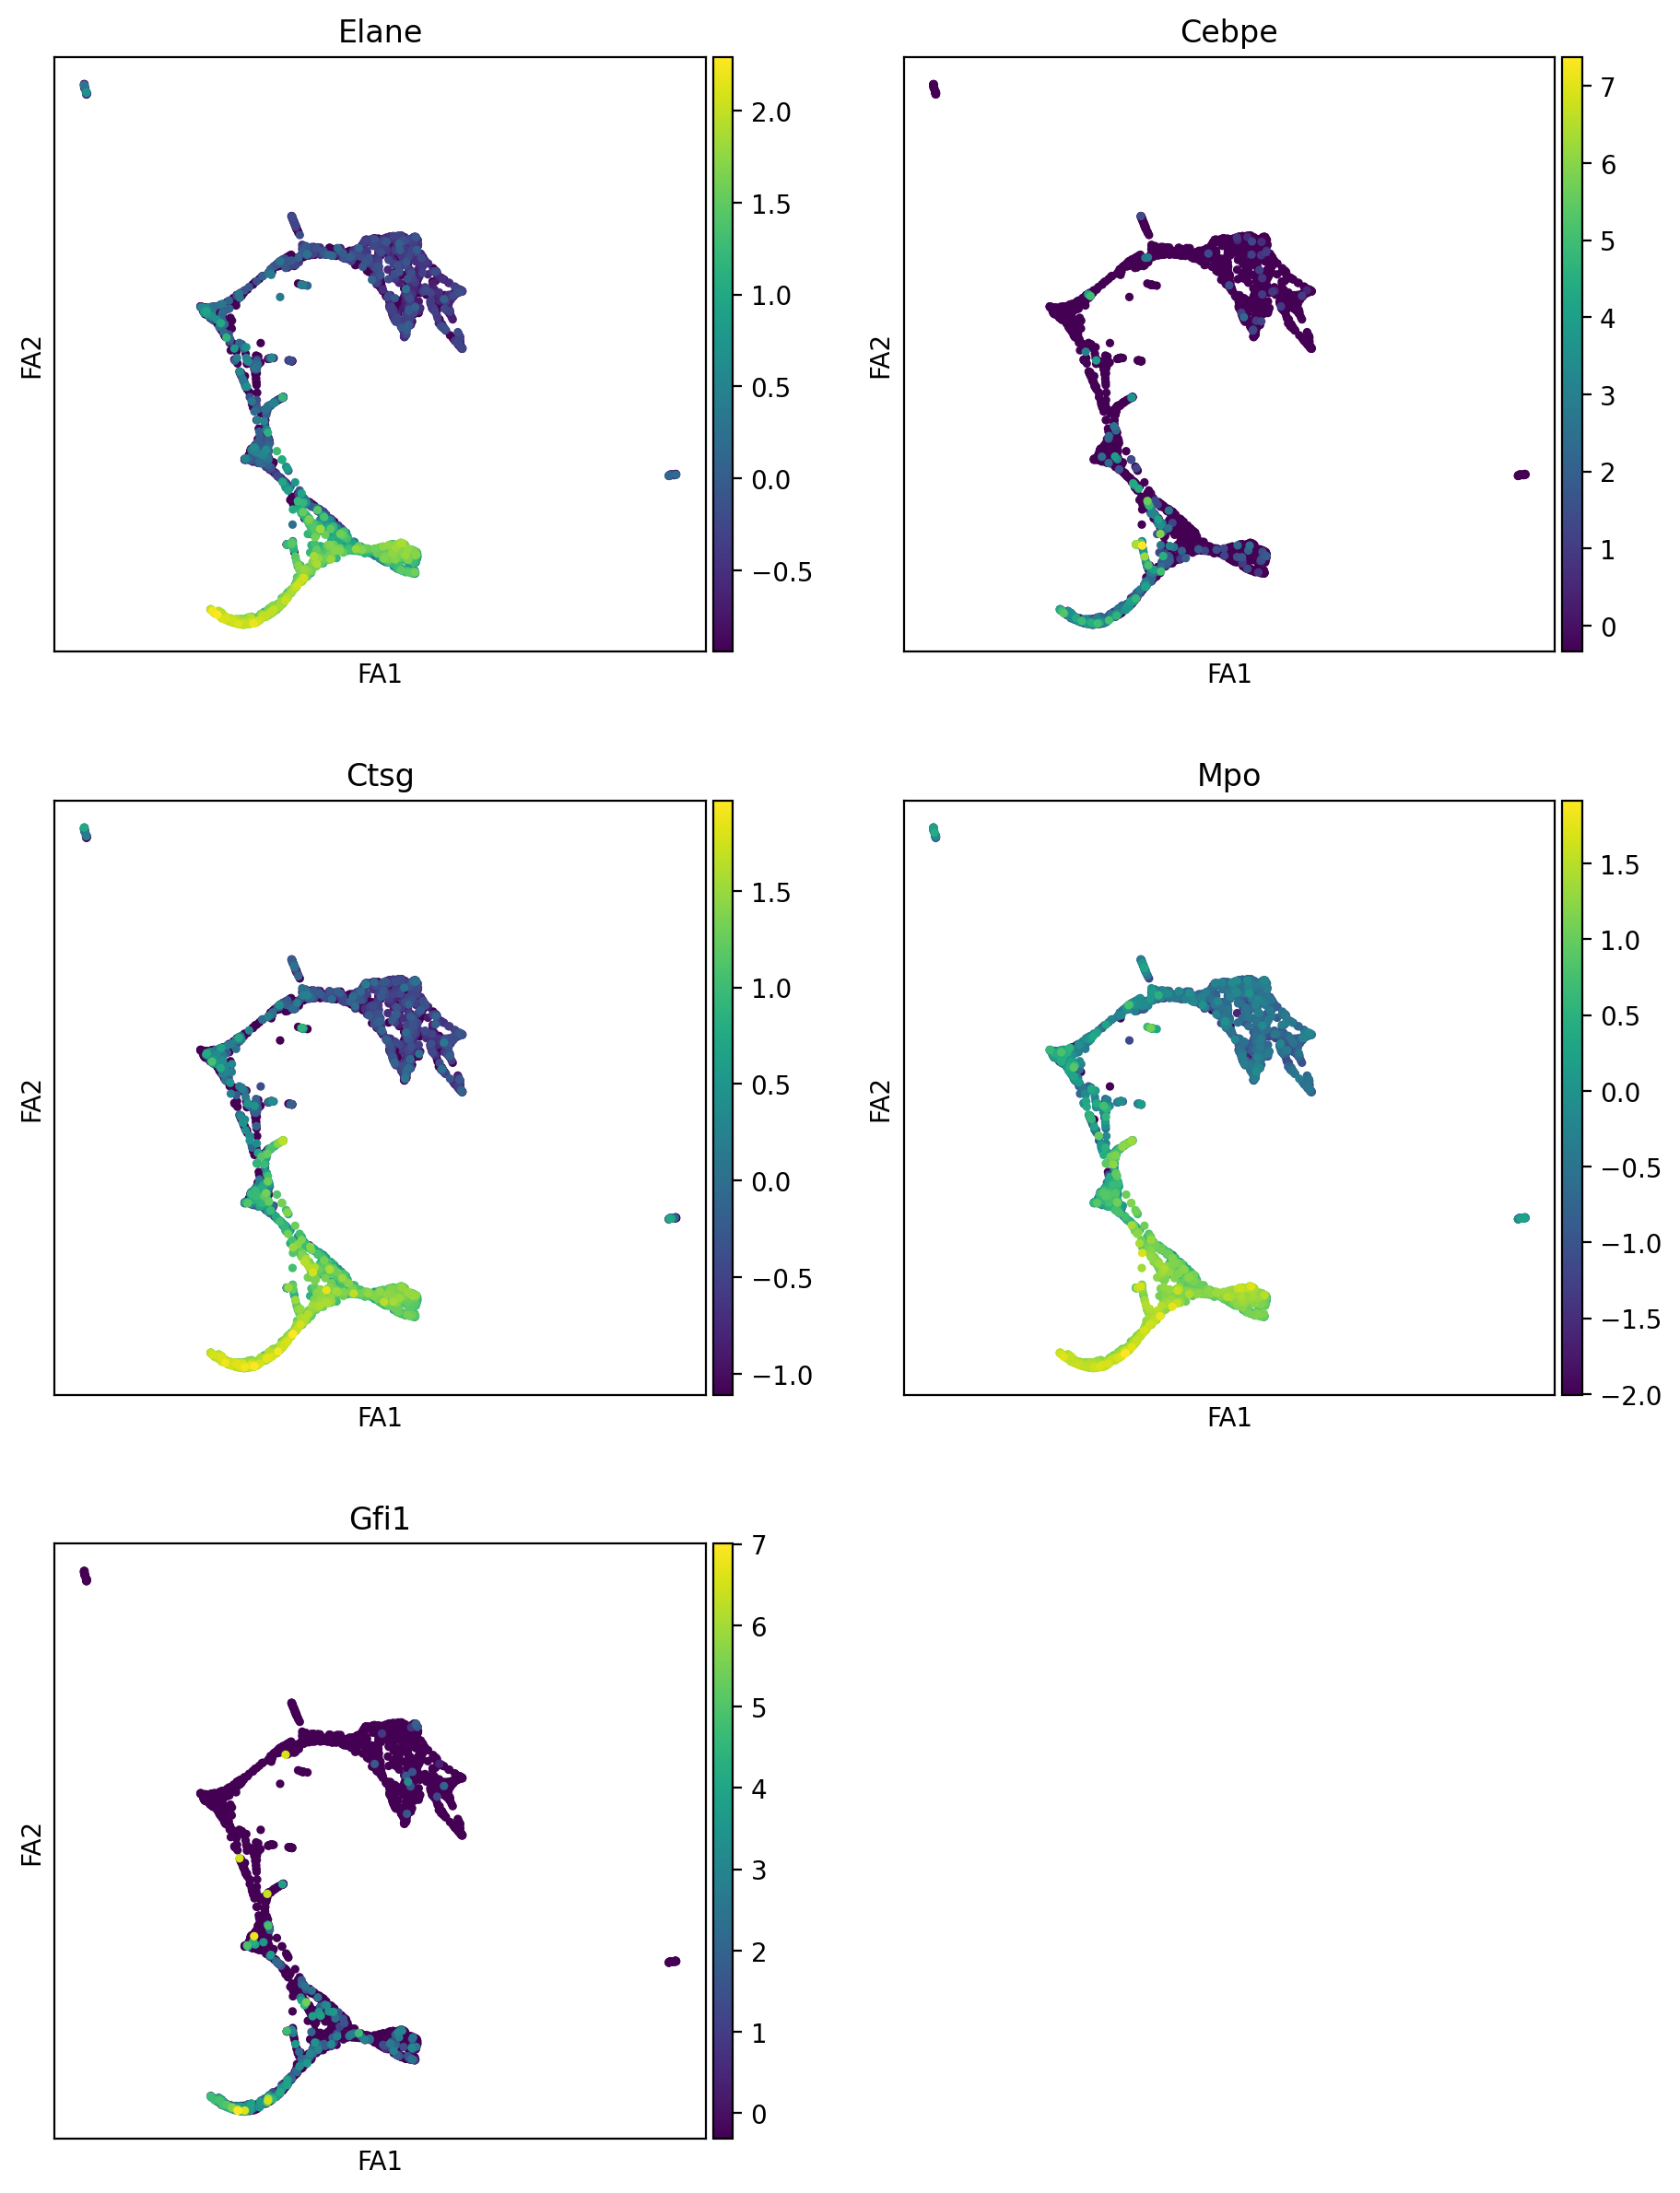

marker gene of Monocytes


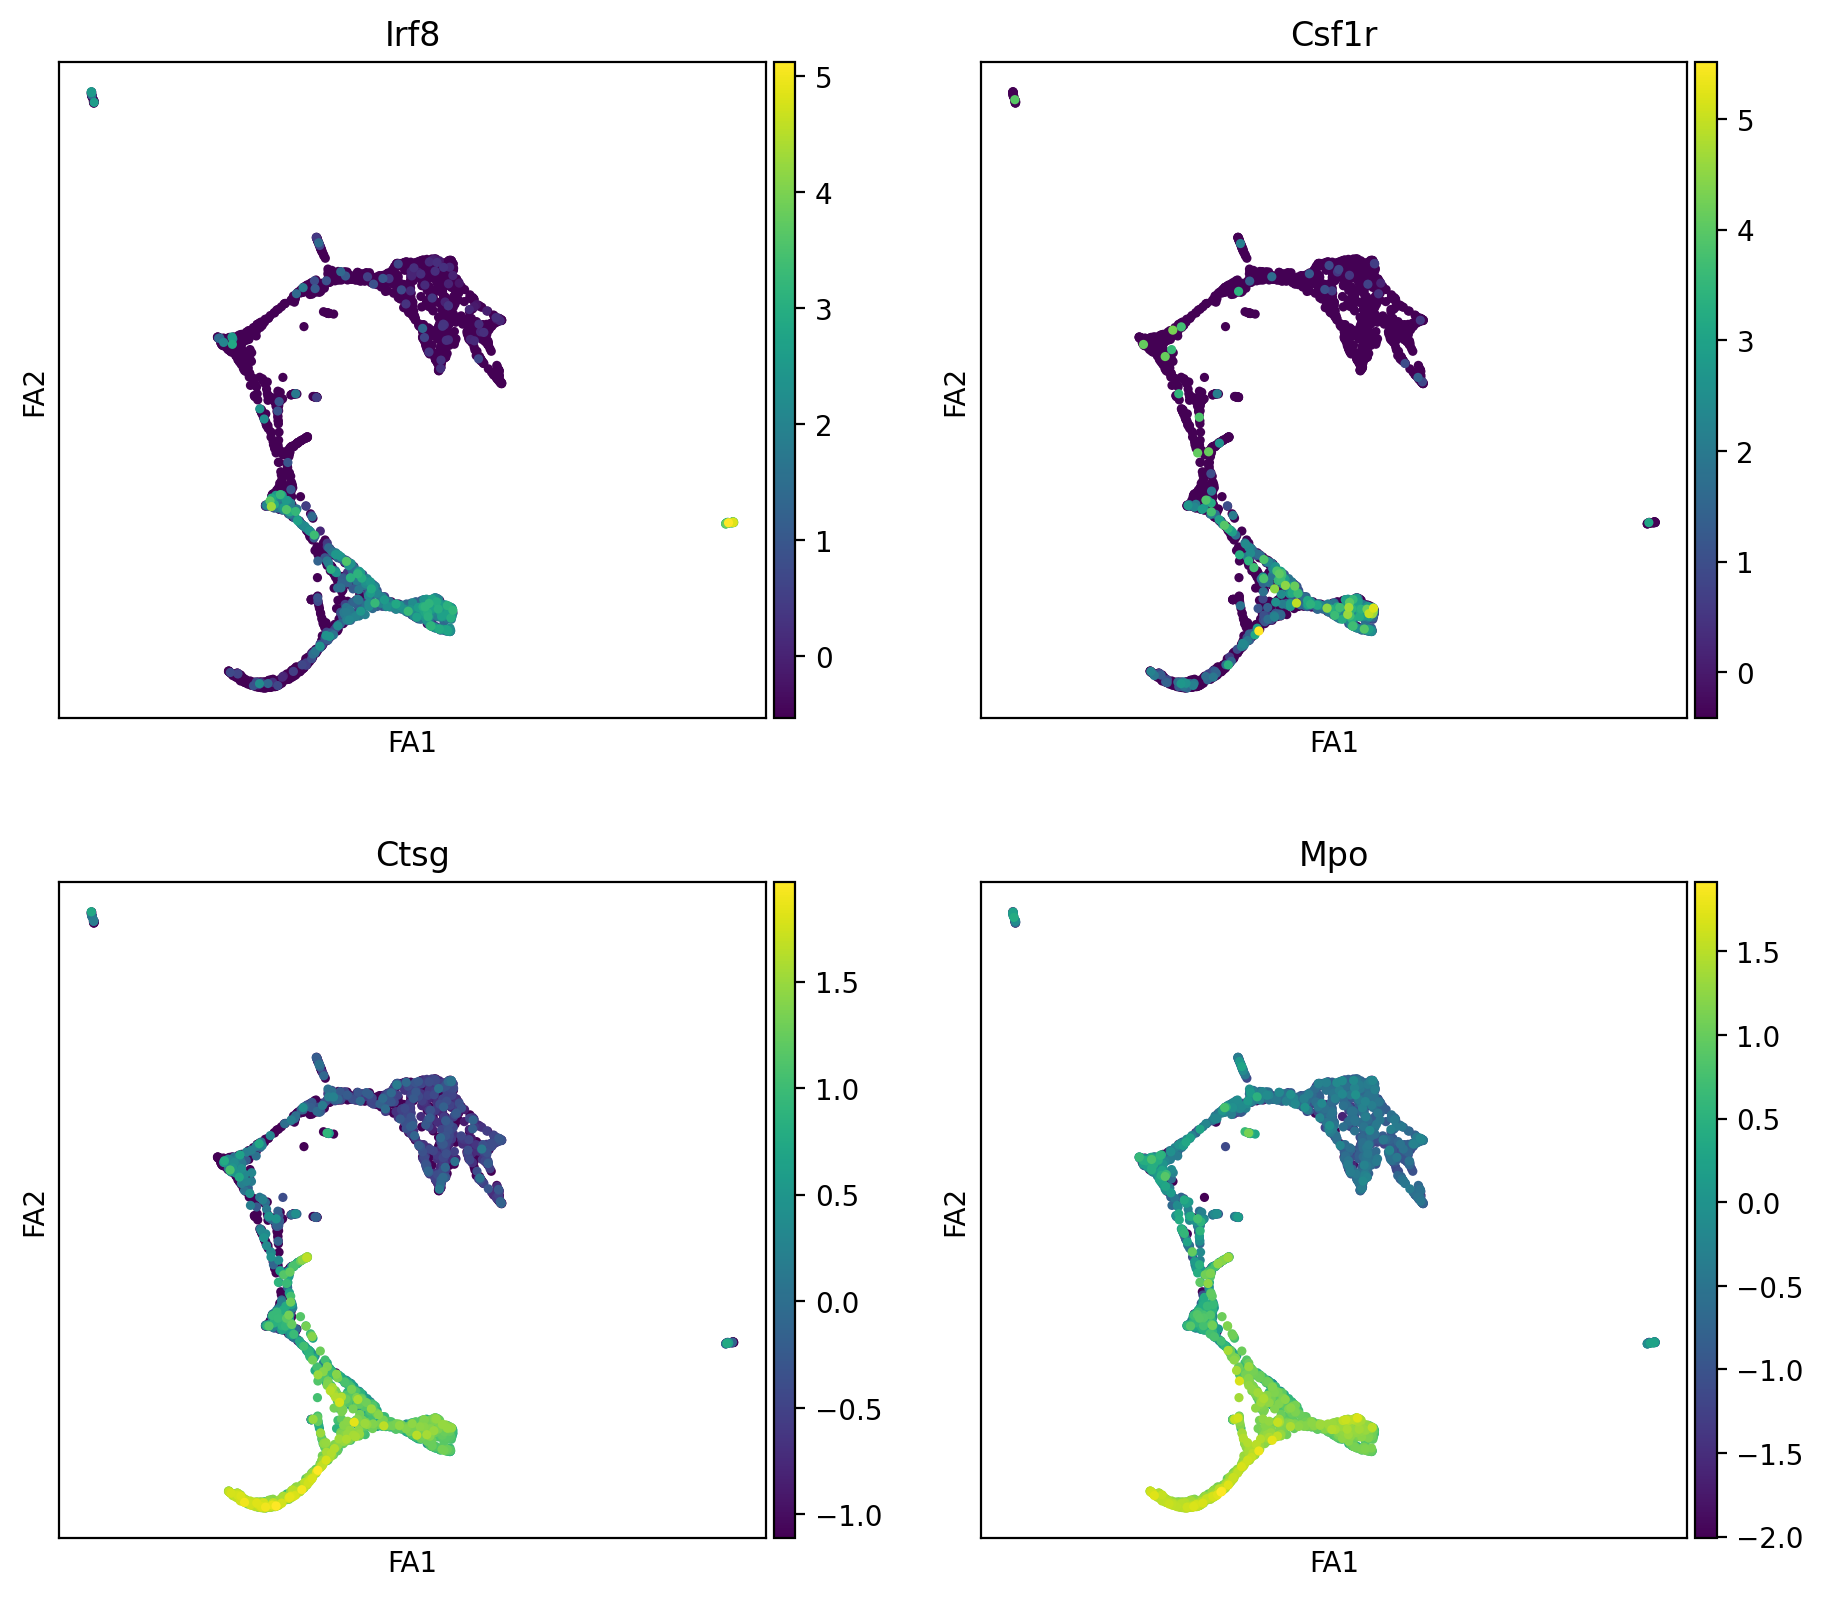

marker gene of Mast_cells


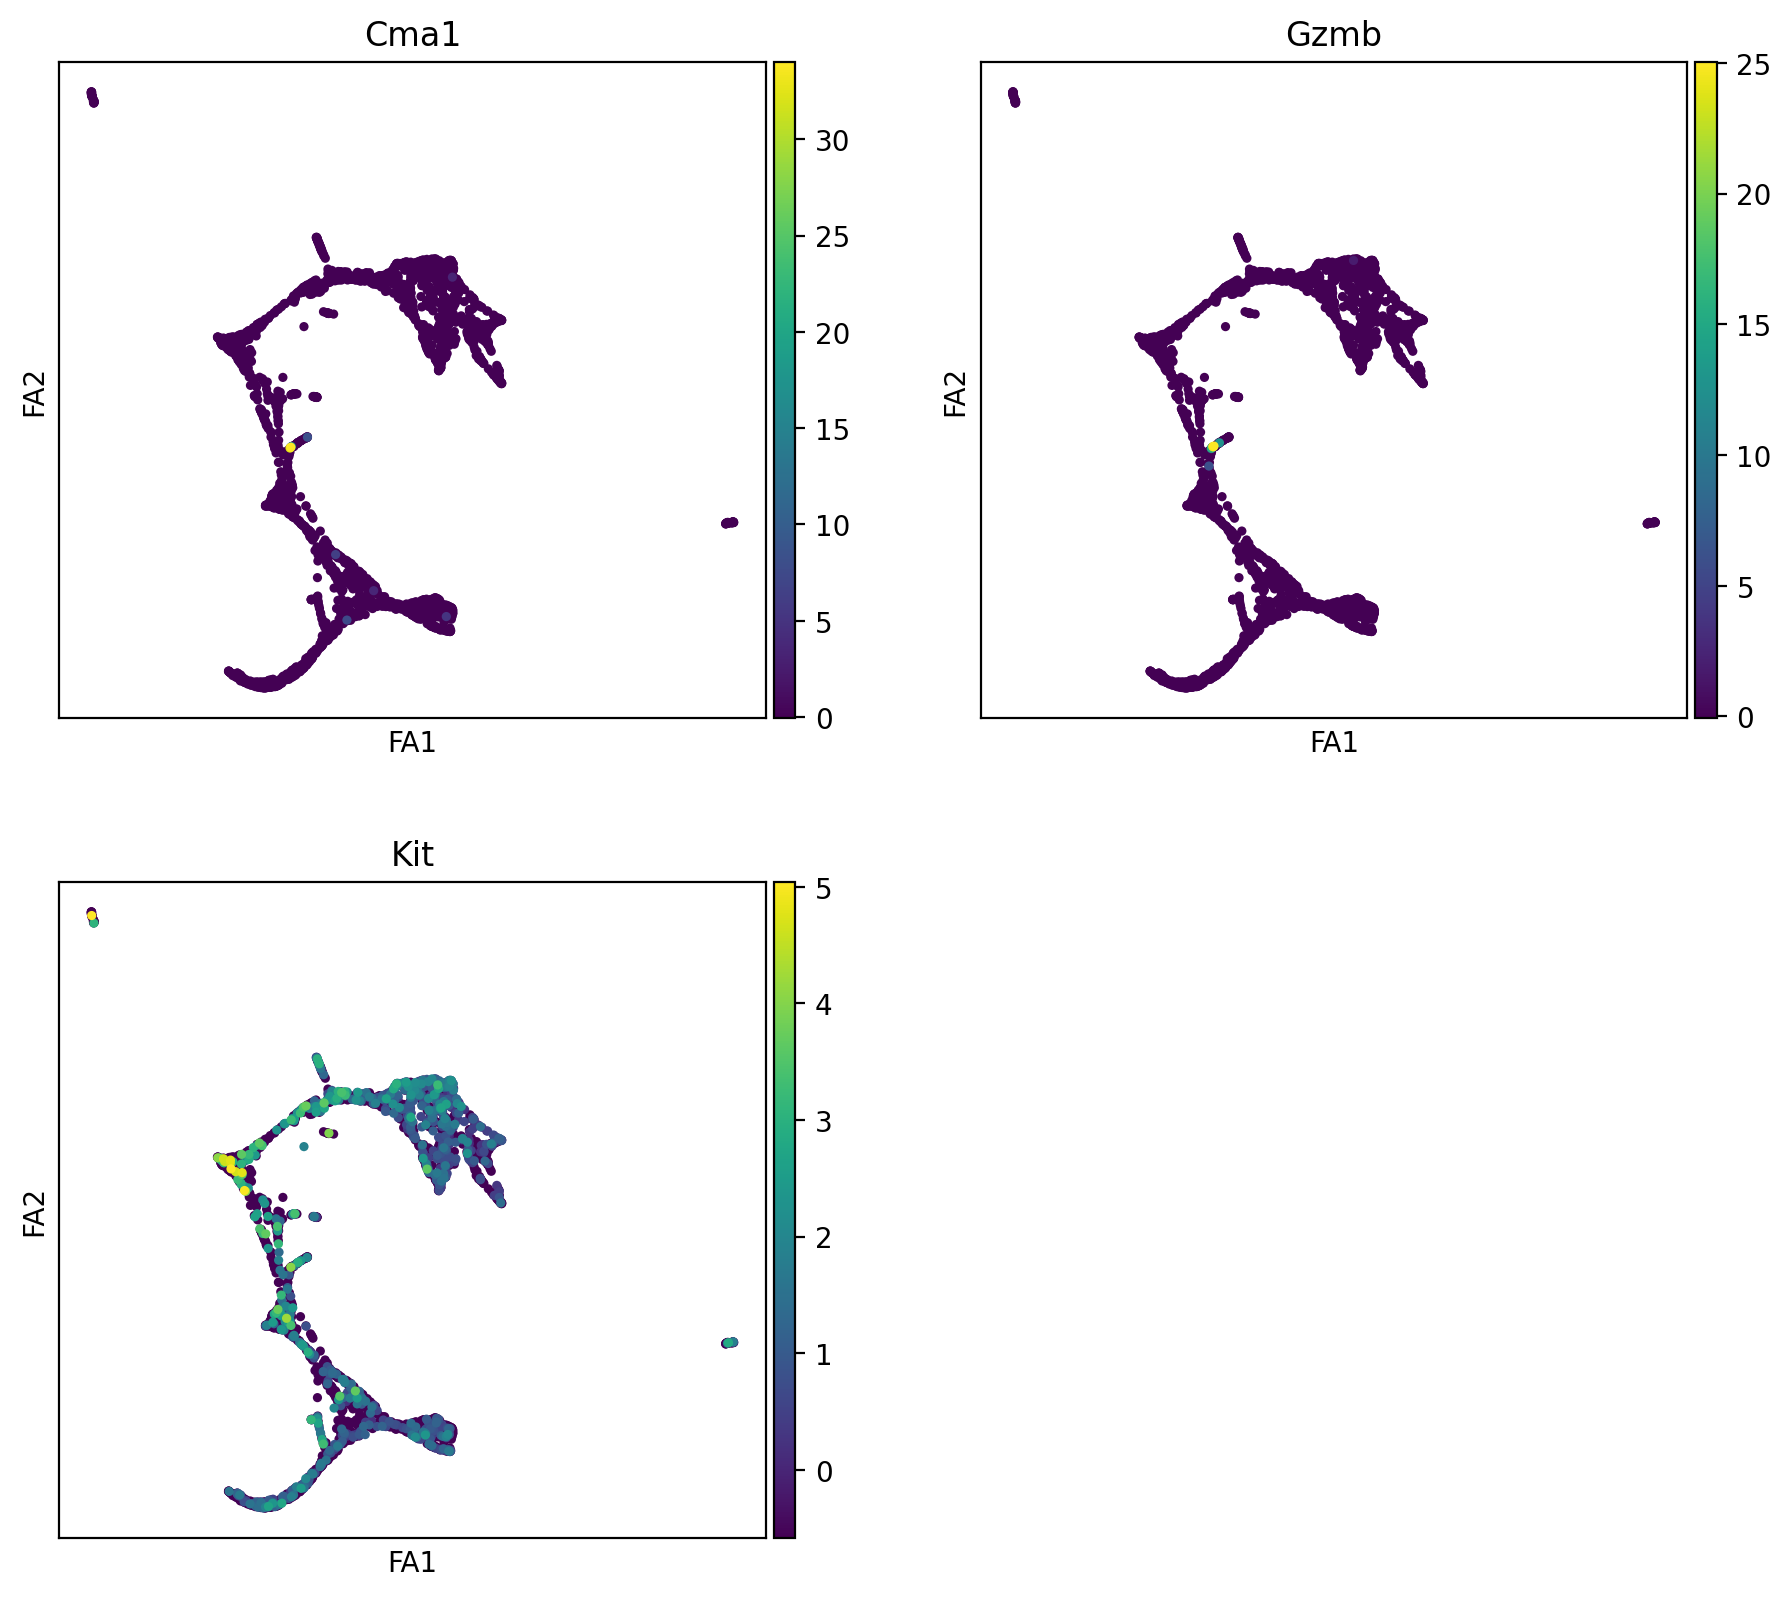

marker gene of Basophils


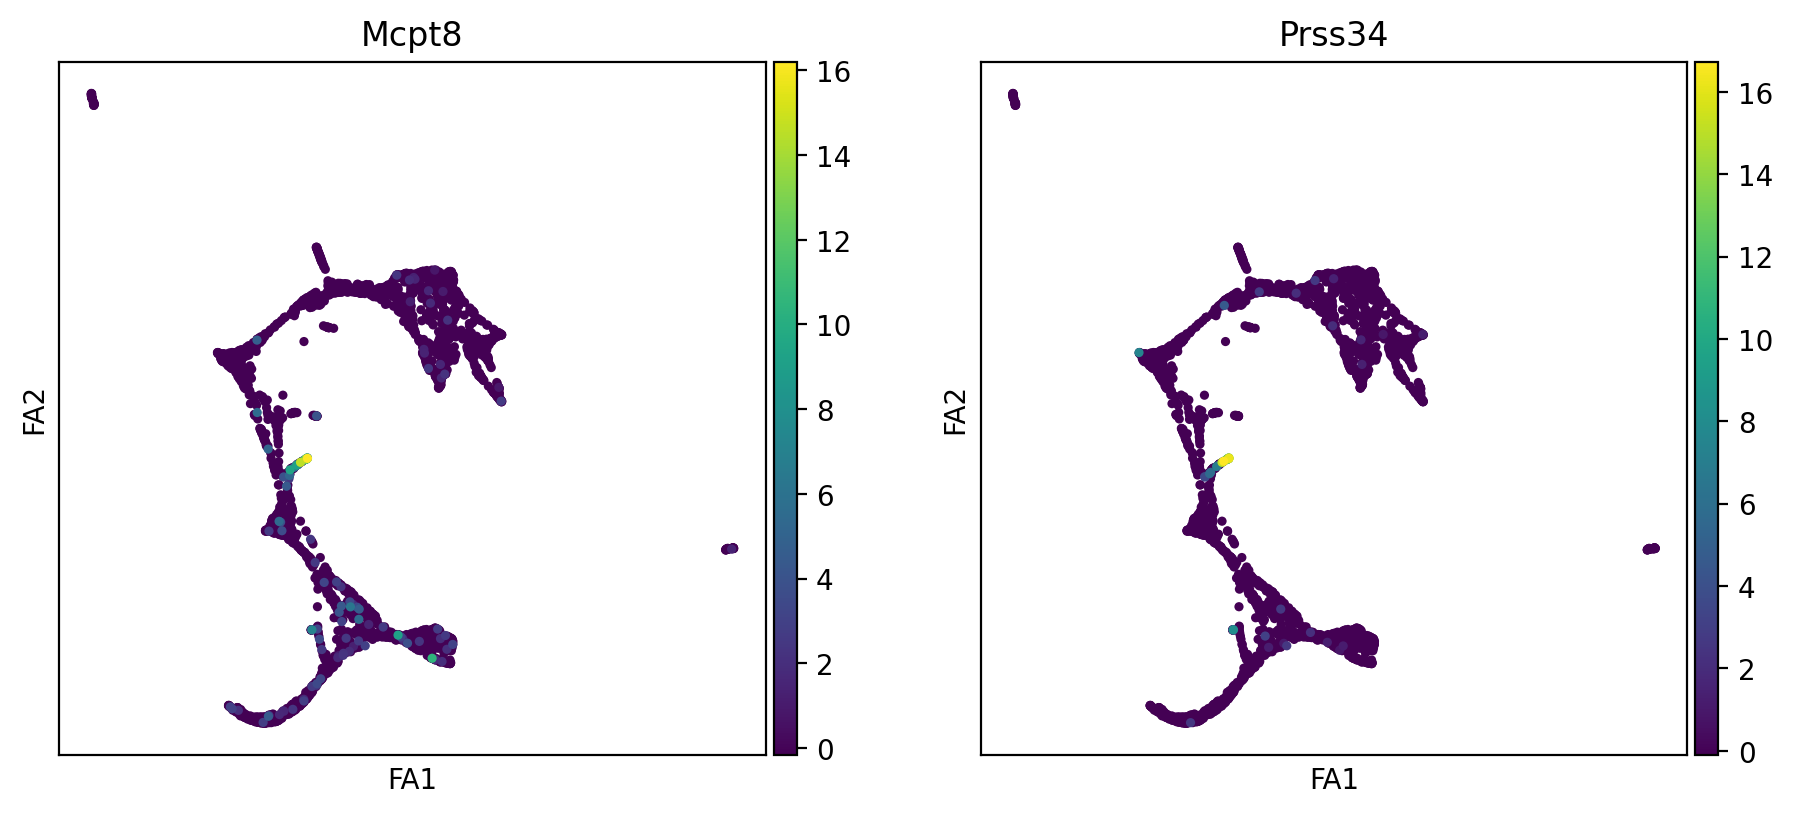

In [21]:
markers = {"Erythroids":["Gata1", "Klf1", "Gypa", "Hba-a2"],
           "Megakaryocytes":["Itga2b", "Pbx1", "Sdpr", "Vwf"],
            "Granulocytes":["Elane", "Cebpe", "Ctsg", "Mpo", "Gfi1"],
            "Monocytes":["Irf8", "Csf1r", "Ctsg", "Mpo"],
            "Mast_cells":["Cma1", "Gzmb", "Kit"],
            "Basophils":["Mcpt8", "Prss34"]
            }

for cell_type, genes in markers.items():
    print(f"marker gene of {cell_type}")
    sc.pl.draw_graph(adata, color=genes, use_raw=False, ncols=2)
    plt.show()



# 10. [Optional step] Cluster annotation

We will annotate the clusters based on the marker gene expression.


## 9.1. Make annotation (1)

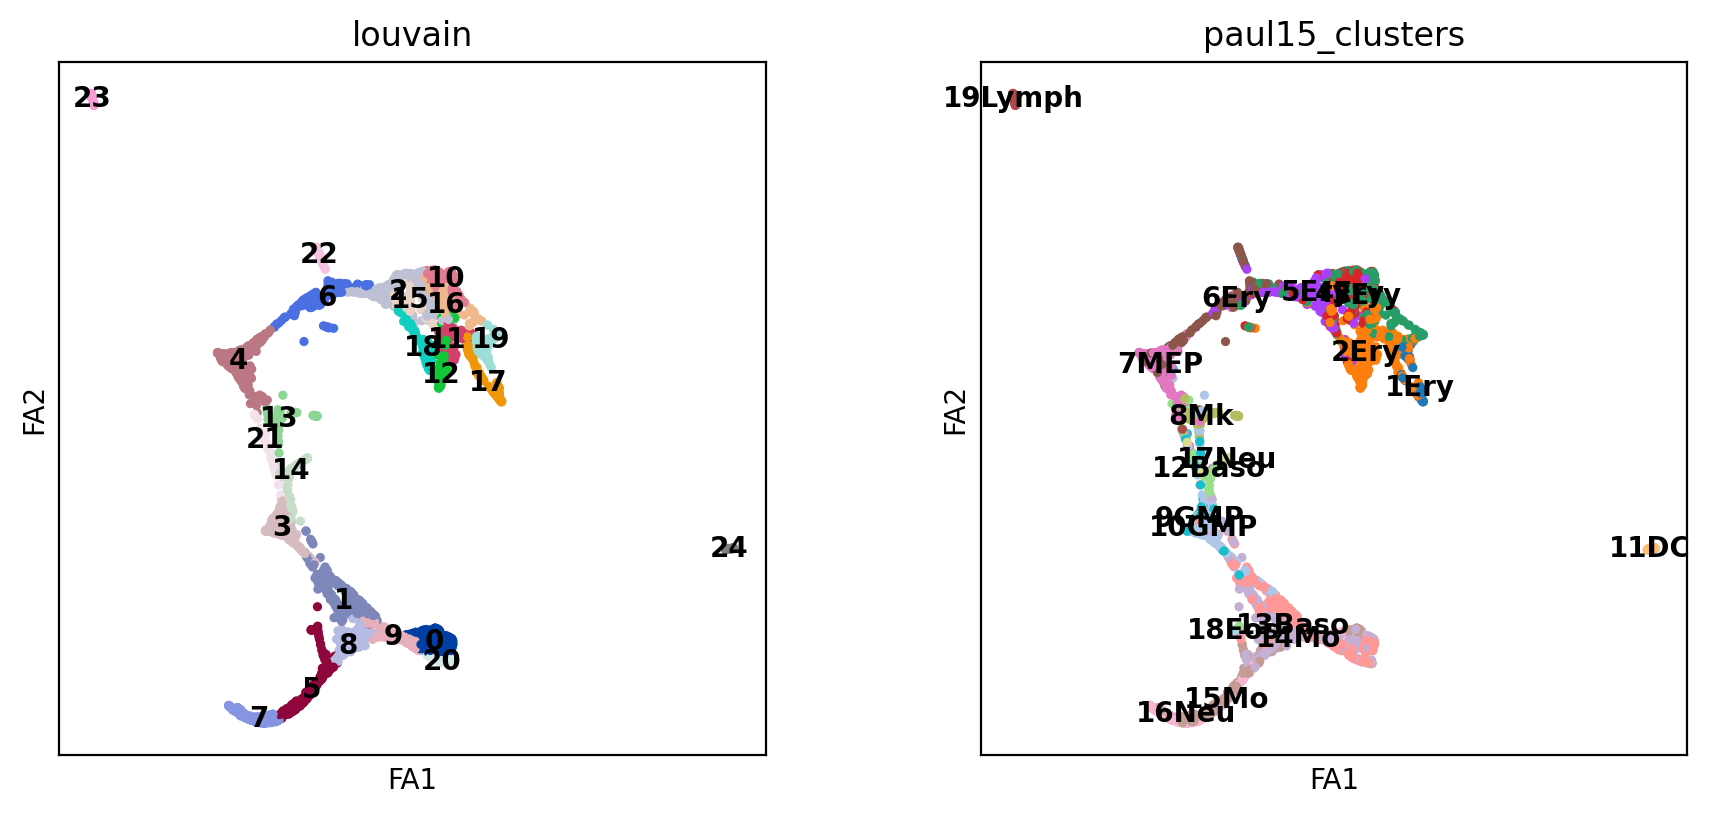

In [22]:
sc.pl.draw_graph(adata, color=['louvain', 'paul15_clusters'],
                 legend_loc='on data')

In [23]:
# Check current cluster name
cluster_list = adata.obs.louvain.unique()
cluster_list

['4', '0', '19', '5', '1', ..., '15', '20', '22', '24', '21']
Length: 25
Categories (25, object): ['0', '1', '2', '3', ..., '21', '22', '23', '24']

#### Attention!! Please change the dictionary below depending on the clustering results. The results may change depending on the execution environment.

In [24]:
# Make cluster anottation dictionary
annotation = {"MEP":[4],
              "Erythroids": [22, 6, 2, 15, 10, 16, 18, 11, 12, 19, 17],
              "Megakaryocytes":[13, 21],  
              "GMP":[3, 14],
              "late_GMP" :[1],   
              "Granulocytes":[7, 5, 8],
              "Monocytes":[9, 20, 0],
              "DC":[24],
              "Lymphoid":[23]}

# Change dictionary format
annotation_rev = {}
for i in cluster_list:
    for k in annotation:
        if int(i) in annotation[k]:
            annotation_rev[i] = k
            
# Check dictionary
annotation_rev

{'4': 'MEP',
 '0': 'Monocytes',
 '19': 'Erythroids',
 '5': 'Granulocytes',
 '1': 'late_GMP',
 '6': 'Erythroids',
 '17': 'Erythroids',
 '12': 'Erythroids',
 '14': 'GMP',
 '8': 'Granulocytes',
 '2': 'Erythroids',
 '10': 'Erythroids',
 '13': 'Megakaryocytes',
 '3': 'GMP',
 '7': 'Granulocytes',
 '18': 'Erythroids',
 '9': 'Monocytes',
 '23': 'Lymphoid',
 '16': 'Erythroids',
 '11': 'Erythroids',
 '15': 'Erythroids',
 '20': 'Monocytes',
 '22': 'Erythroids',
 '24': 'DC',
 '21': 'Megakaryocytes'}

In [25]:
adata.obs["cell_type"] = [annotation_rev[i] for i in adata.obs.louvain]

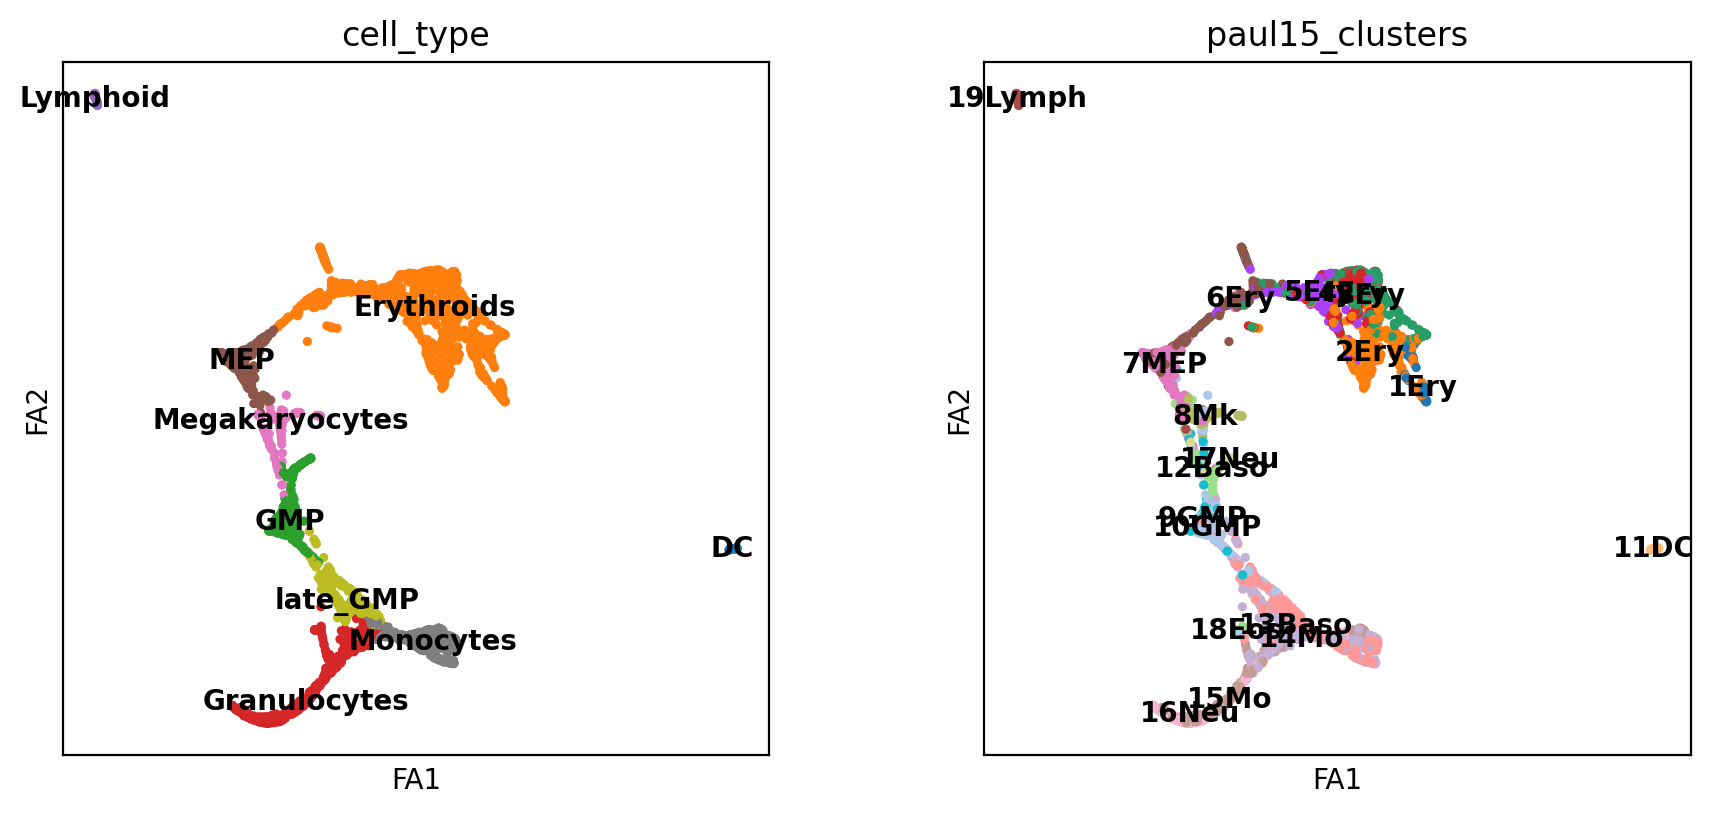

In [26]:
# check results
sc.pl.draw_graph(adata, color=['cell_type', 'paul15_clusters'],
                 legend_loc='on data')

## 10.2. Make annotation (2)
We'll also annotate the indivisual Louvain clusters.

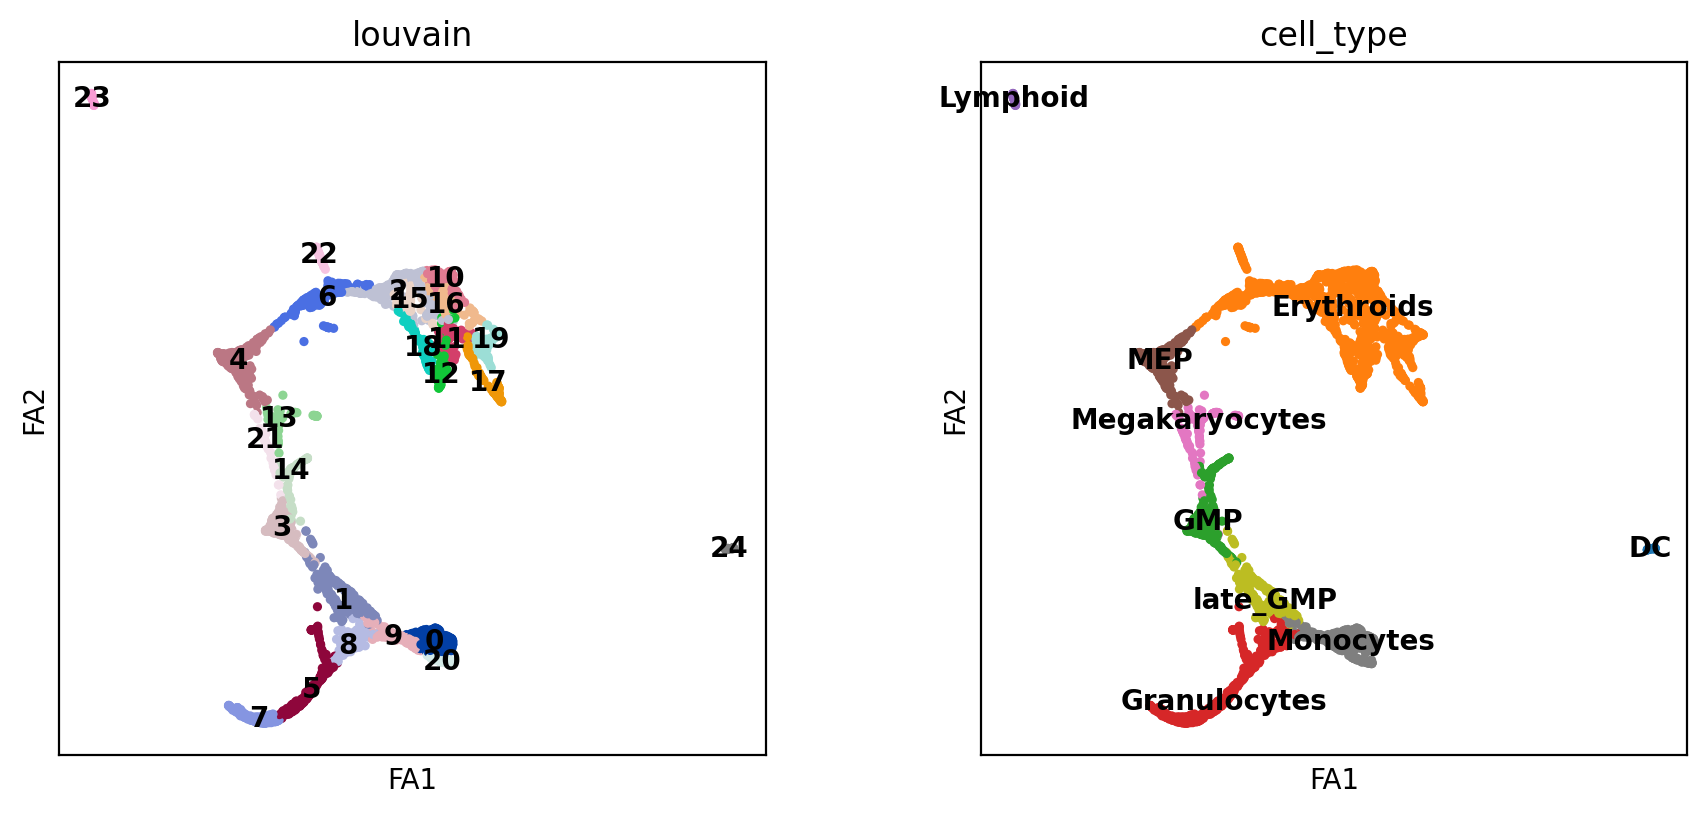

In [27]:
sc.pl.draw_graph(adata, color=['louvain', 'cell_type'],
                 legend_loc='on data')

#### !! Please change the dictionary below depending on the clustering results. The results may change depending on the execution environment.

In [ ]:
annotation_2 = {'4': 'MEP_0',
                '15': 'Ery_0',
                '10': 'Ery_1',
                '16': 'Ery_2',
                '14': 'Ery_3',
                '9': 'Ery_4',
                '8': 'Ery_5',
                '19': 'Ery_6',
                '3': 'Ery_7',
                '12': 'Ery_8',
                '18': 'Ery_9',
                '17': 'Mk_0',
                '22': 'Mk_0',
                '11': 'GMP_0',
                '1': 'GMP_1',
                '0': 'GMPl_0',
                '7': 'Gran_0',
                '13': 'Gran_1',
                '4': 'Gran_2',
                '6': 'Mo_0',
                '2': 'Mo_1',
                '21': 'DC_0',
                '20': 'Lym_0'}

In [27]:
adata.obs["louvain_annot"] = [annotation_2[i] for i in adata.obs.louvain]

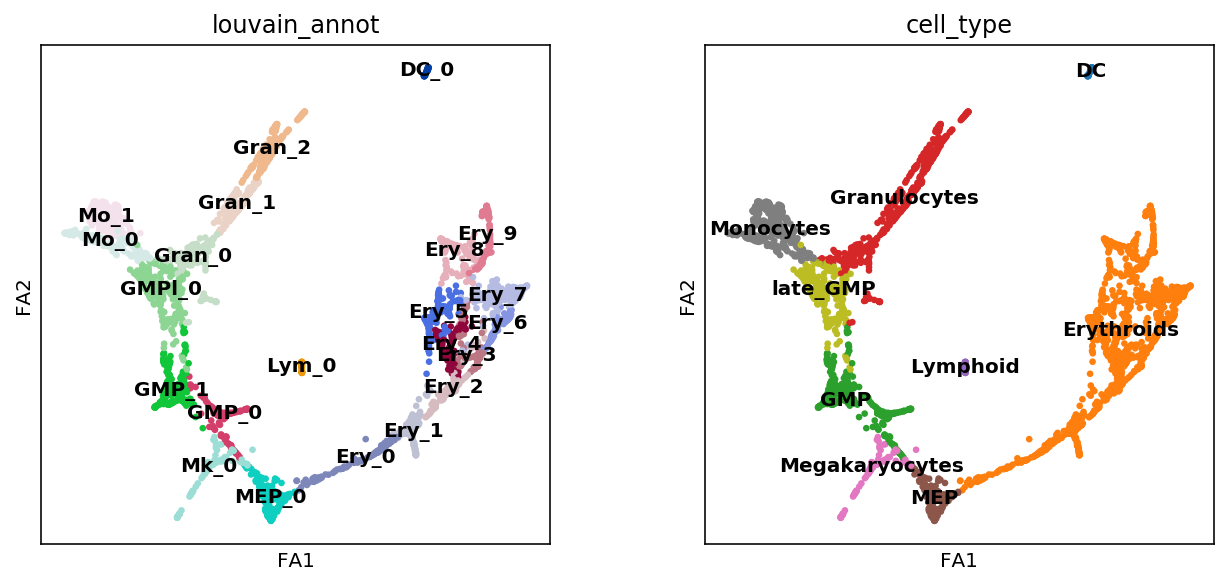

In [28]:
# Check result
sc.pl.draw_graph(adata, color=['louvain_annot', 'cell_type'],
                 legend_loc='on data')

# 11. [Optional step] Subset cells

During the CellOracle analysis, we will focus on the myeloid lineage. Since the othre clusters (i.e. the DC and lymphoid clusters) will not be analyzed, we will choose to remove them now.

It is also important to ensure that the differentiation trajectories are smoothly connected; CellOracle works best with continuous trajectories. If there is discrete cell cluster or non-related cell contamination, please remove them prior to celloracle analysis.

In [28]:
adata.obs.cell_type.unique()

['MEP', 'Monocytes', 'Erythroids', 'Granulocytes', 'late_GMP', 'GMP', 'Megakaryocytes', 'Lymphoid', 'DC']
Categories (9, object): ['DC', 'Erythroids', 'GMP', 'Granulocytes', ..., 'MEP', 'Megakaryocytes', 'Monocytes', 'late_GMP']

In [29]:
cell_of_interest = adata.obs.index[~adata.obs.cell_type.isin(["Lymphoid", "DC"])]
adata = adata[cell_of_interest, :]

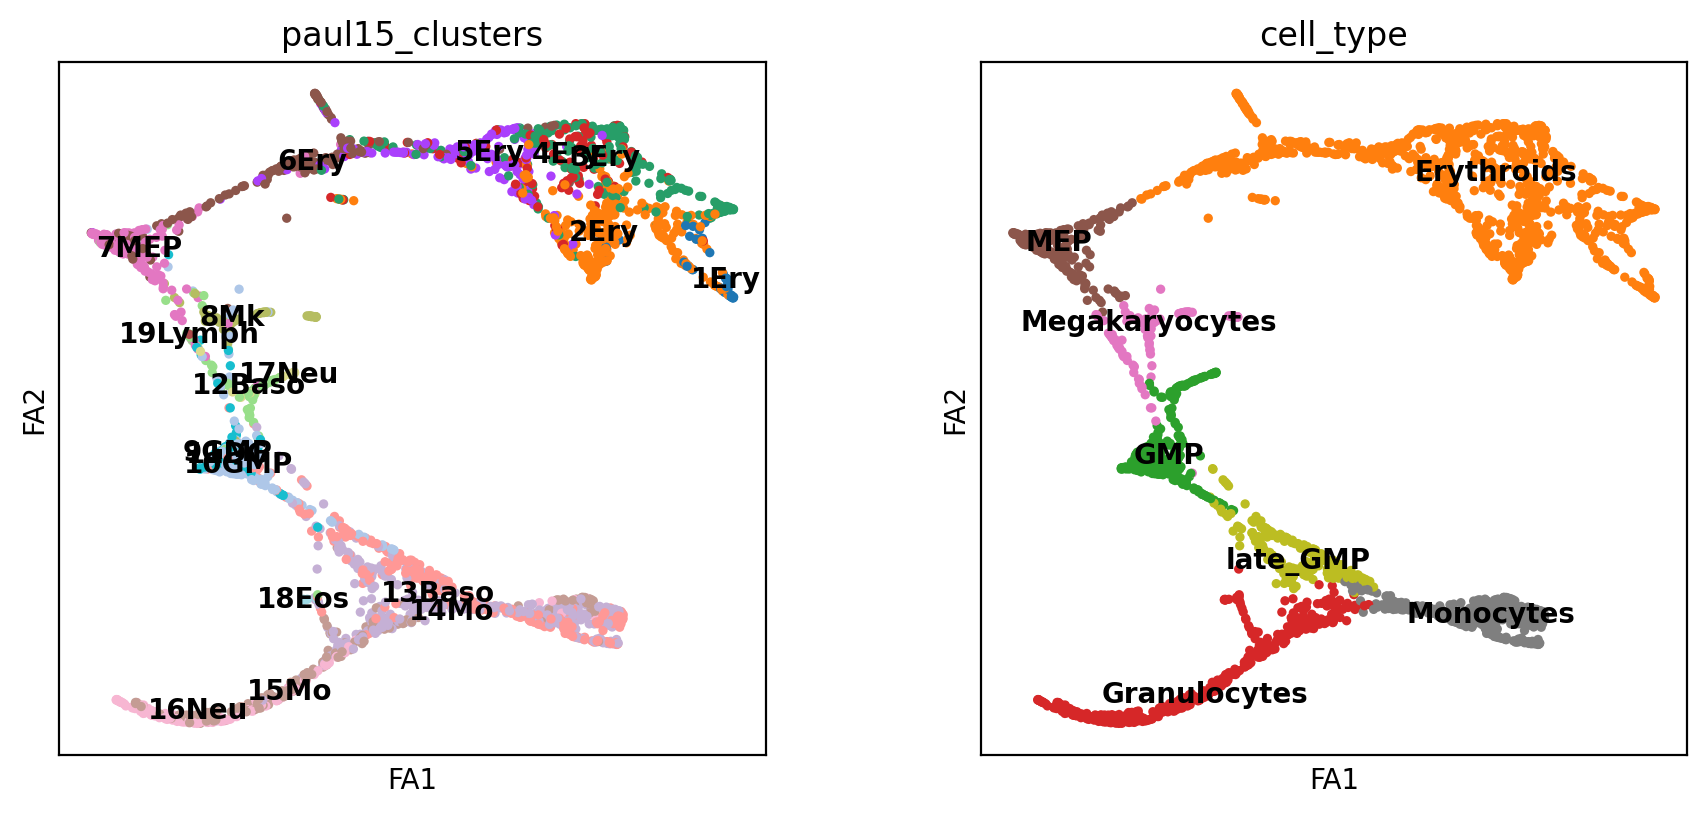

In [31]:
# check result
sc.pl.draw_graph(adata, color=['paul15_clusters', 'cell_type'],
                 legend_loc='on data')

# 12. Save processed data

In [32]:
adata.write_h5ad("Paul_etal_15.h5ad")